# Python · WarpKriging — non-stationarity, categorical and ordinal inputs

**Idea.** Input warpings handle non-stationarity and categorical or ordinal inputs;
each warping must beat, or at least match, plain Kriging where it is meant to help,
without making the predictive variance overconfident.

**Reference.** Plain `Kriging` on the same data (accuracy and NLPD), and `none`
warping = `Kriging`.

**Tags.** class: WarpKriging, Kriging ·
warping: none, affine, boxcox, kumaraswamy, neural_mono, categorical, ordinal ·
topic: non-stationarity, categorical inputs

`WarpKriging` learns a transform per input variable jointly with the GP
hyperparameters. Problems where a plain stationary GP is the wrong model:

| case | function | warp |
|---|---|---|
| 1D non-stationary | Gramacy & Lee (2012): fast oscillation on the left, flat on the right | `kumaraswamy`, `knots(5)`, `neural_mono(8)`, `boxcox`, `affine` |
| 2D non-stationary | Gramacy & Lee (2008): a bump in a corner of [−2, 6]² | `kumaraswamy` × 2 |
| mixed continuous / categorical | Branin + a level-dependent shift and scale | `categorical(5,2)`, `none` |
| mixed continuous / ordinal | Hartmann 3 with x₁ observed on 6 ordered levels | `ordinal(6)` |

Checks: all-`none` warping reproduces plain `Kriging`; a noise-free
`WarpKriging` interpolates; predictions are finite; and (warn-level) the warps
beat plain `Kriging` where they are meant to.

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylibkriging as lk

import gallery
from gallery import TESTS, design, metrics, compat

suite = gallery.Suite("warpings-categorical-ordinal_WarpKriging_python")
print("pylibkriging", compat.version())
if not compat.has("WarpKriging"):
    suite.check_skip("WarpKriging", "not available in this pylibkriging")


def pred(k, X):
    m, s, *_ = k.predict(X, return_stdev=True)
    return np.ravel(m), np.ravel(s)


BASE_NLPD = {}


def evaluate(case, label, k, X, y, Xt, yt):
    m, s = pred(k, Xt)
    res = metrics.all_metrics(yt, m, s)
    # calibration: a warp must not make the stdev collapse where the error is not small
    if label.startswith("Kriging"):
        BASE_NLPD[case] = res["nlpd"]
    else:
        suite.check_less(f"{case}/{label}: NLPD - NLPD(Kriging) (overconfident stdev?)", res["nlpd"] - BASE_NLPD[case],
                   2.0, severity="warn", detail=f"min stdev {np.min(s):.3g}, max |error|/stdev "
                   f"{np.max(np.abs(yt - m) / np.maximum(s, 1e-300)):.3g}")
    suite.metric(case, label, ll=float(k.logLikelihood()), **res)
    suite.check_finite(f"{case}/{label}: predictions finite", m)
    mX, _ = pred(k, X)
    suite.check_less(f"{case}/{label}: interpolates (max |m(X)-y| / sd(y))", np.max(np.abs(mX - y)) / np.std(y), 1e-3,
               severity="warn")
    return res

pylibkriging 1.2.2


## `none` warping == plain Kriging

In [3]:
if compat.has("WarpKriging"):
    tf = TESTS["branin"]
    X, y, Xt, yt = design.dataset(tf, 30, n_test=500, seed=31)
    for kernel in ["gauss", "matern5_2"]:
        kp = lk.Kriging(y, X, kernel)
        kw = lk.WarpKriging(y, X, ["none", "none"], kernel)
        suite.check_close(f"{kernel}: WarpKriging(none) LL == Kriging LL", kw.logLikelihood(), kp.logLikelihood(),
                    rtol=1e-3, severity="warn")
        suite.check_close(f"{kernel}: WarpKriging(none) mean == Kriging mean", pred(kw, Xt)[0], pred(kp, Xt)[0],
                    rtol=1e-2, atol=1e-2 * np.std(y), severity="warn")

[WARN] gauss: WarpKriging(none) LL == Kriging LL: value=0.0094654 expected rtol 0.001, atol 0 
[WARN] gauss: WarpKriging(none) mean == Kriging mean: value=12.9497 expected rtol 0.01, atol 0.491995 


## 1D non-stationary: Gramacy & Lee (2012)

[WARN] gl2012/boxcox: NLPD - NLPD(Kriging) (overconfident stdev?): value=280.157 expected < 2 min stdev 1.29e-05, max |error|/stdev 749
[WARN] gl2012/kumaraswamy: NLPD - NLPD(Kriging) (overconfident stdev?): value=2.07775e+06 expected < 2 min stdev 1.27e-05, max |error|/stdev 2.42e+04
[WARN] gl2012/knots(5): NLPD - NLPD(Kriging) (overconfident stdev?): value=1.91865e+06 expected < 2 min stdev 1.33e-05, max |error|/stdev 2.33e+04


metric,ll,rmse,q2,nlpd,coverage95,crps
package,,,,,,
Kriging,-28.0207,0.1673,0.9812,-1.089200e+00,0.916,0.0691
affine,-28.0207,0.1673,0.9812,-1.089200e+00,0.916,0.0691
boxcox,-27.3349,0.1818,0.9778,2.790680e+02,0.999,0.0640
kumaraswamy,-27.2423,0.2205,0.9673,2.077750e+06,0.983,0.0741
knots(5),-26.1683,0.1875,0.9763,1.918650e+06,0.812,0.0891
neural_mono(8),-27.9898,0.1605,0.9827,-9.203000e-01,0.916,0.0685


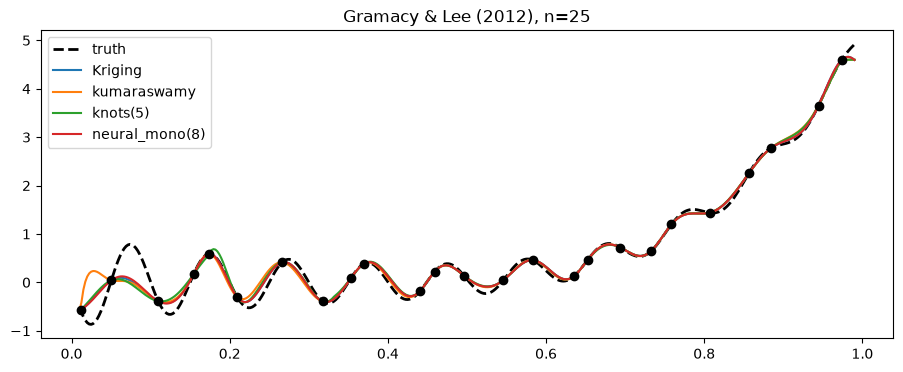

In [4]:
WARPS_1D = ["affine", "boxcox", "kumaraswamy", "knots(5)", "neural_mono(8)"]
if compat.has("WarpKriging"):
    tf = TESTS["gramacy_lee_2012"]
    X, y, Xt, yt = design.dataset(tf, 25, n_test=1000, seed=32)
    X = X * 0.98 + 0.01; Xt = Xt * 0.98 + 0.01  # strictly inside (0,1) for boxcox/kumaraswamy
    y, yt = tf.unit(X), tf.unit(Xt)
    base = evaluate("gl2012", "Kriging", lk.Kriging(y, X, "matern5_2"), X, y, Xt, yt)
    fits = {}
    for w in WARPS_1D:
        with suite.check_runs(f"gl2012/{w}: fit"):
            fits[w] = lk.WarpKriging(y, X, [w], "matern5_2")
            evaluate("gl2012", w, fits[w], X, y, Xt, yt)
    t = suite.table().loc["gl2012"]
    best = t.drop(index="Kriging")["rmse"].min()
    suite.check_less("gl2012: best warp RMSE / Kriging RMSE", best / base["rmse"], 1.0, severity="warn")
    u = np.linspace(0.01, 0.99, 400)[:, None]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(u, tf.unit(u), "k--", lw=2, label="truth")
    ax.plot(u, pred(lk.Kriging(y, X, "matern5_2"), u)[0], label="Kriging")
    for w in ["kumaraswamy", "knots(5)", "neural_mono(8)"]:
        if w in fits:
            ax.plot(u, pred(fits[w], u)[0], label=w)
    ax.plot(X, y, "ko"); ax.legend(); ax.set_title("Gramacy & Lee (2012), n=25")
    display(t.round(4))

## 2D non-stationary: Gramacy & Lee (2008)

In [5]:
if compat.has("WarpKriging"):
    tf = TESTS["gramacy_lee_2008"]
    X, y, Xt, yt = design.dataset(tf, 40, n_test=2000, seed=33)
    X = X * 0.98 + 0.01; Xt = Xt * 0.98 + 0.01
    y, yt = tf.unit(X), tf.unit(Xt)
    base = evaluate("gl2008", "Kriging", lk.Kriging(y, X, "matern5_2"), X, y, Xt, yt)
    with suite.check_runs("gl2008/kumaraswamy: fit"):
        res = evaluate("gl2008", "kumaraswamy", lk.WarpKriging(y, X, ["kumaraswamy"] * 2, "matern5_2"),
                       X, y, Xt, yt)
        suite.check_less("gl2008: RMSE(kumaraswamy) / RMSE(Kriging)", res["rmse"] / base["rmse"], 1.0, severity="warn")

[WARN] gl2008: RMSE(kumaraswamy) / RMSE(Kriging): value=1.18165 expected < 1 


## Mixed continuous / categorical

y = a_c · Branin(x₁, x₂) + b_c for a level c ∈ {0..4} with level-specific
(a_c, b_c): two pairs of levels are close, the fifth one is different. The
categorical variable is passed as its level index 0..L−1.

In [6]:
if compat.has("WarpKriging"):
    tf = TESTS["branin"]
    L = 5
    a = np.array([1.0, 1.05, 0.6, 0.65, -0.5])
    b = np.array([0.0, 5.0, 40.0, 45.0, 100.0])

    def mixed(Xc):
        c = Xc[:, 0].astype(int)
        return a[c] * tf.unit(Xc[:, 1:]) + b[c]

    def mixed_design(n, seed):
        rng = np.random.default_rng(seed)
        Xc = np.column_stack([np.arange(n) % L, design.lhs(n, 2, seed=seed)])
        return Xc[rng.permutation(n)]

    X = mixed_design(60, 34); Xt = mixed_design(1000, 35)
    y, yt = mixed(X), mixed(Xt)
    base = evaluate("mixed", "Kriging (level as number)", lk.Kriging(y, X, "matern5_2"), X, y, Xt, yt)
    with suite.check_runs("mixed/categorical: fit"):
        kc = lk.WarpKriging(y, X, [f"categorical({L},2)", "none", "none"], "matern5_2")
        res = evaluate("mixed", "categorical(5,2)", kc, X, y, Xt, yt)
        suite.check_less("mixed: RMSE(categorical) / RMSE(level as number)", res["rmse"] / base["rmse"], 1.0,
                   severity="warn")
        suite.check_greater("mixed/categorical: Q2", res["q2"], 0.8, severity="warn")

## Mixed continuous / ordinal

Hartmann 3 with x₁ only observed on 6 non-equally spaced ordered levels; the
model sees the level rank 0..5.

In [7]:
if compat.has("WarpKriging"):
    tf = TESTS["hartmann3"]
    levels = np.array([0.0, 0.05, 0.15, 0.4, 0.8, 1.0])

    def ordinal_design(n, seed):
        U = design.lhs(n, 3, seed=seed)
        r = np.minimum((U[:, 0] * 6).astype(int), 5)
        return np.column_stack([r, U[:, 1:]]).astype(float)

    def f_ord(Xo):
        return tf.unit(np.column_stack([levels[Xo[:, 0].astype(int)], Xo[:, 1:]]))

    X = ordinal_design(60, 36); Xt = ordinal_design(1000, 37)
    y, yt = f_ord(X), f_ord(Xt)
    base = evaluate("ordinal", "Kriging (rank as number)", lk.Kriging(y, X / [5, 1, 1], "matern5_2"),
                    X / [5, 1, 1], y, Xt / [5, 1, 1], yt)
    with suite.check_runs("ordinal/ordinal(6): fit"):
        ko = lk.WarpKriging(y, X, ["ordinal(6)", "none", "none"], "matern5_2")
        res = evaluate("ordinal", "ordinal(6)", ko, X, y, Xt, yt)
        suite.check_less("ordinal: RMSE(ordinal) / RMSE(rank as number)", res["rmse"] / base["rmse"], 1.1,
                   severity="warn")

In [8]:
suite.table().round(4)

metric                                   ll     rmse      q2          nlpd  \
case    package                                                              
gl2012  Kriging                    -28.0207   0.1673  0.9812 -1.089200e+00   
        affine                     -28.0207   0.1673  0.9812 -1.089200e+00   
        boxcox                     -27.3349   0.1818  0.9778  2.790680e+02   
        kumaraswamy                -27.2423   0.2205  0.9673  2.077750e+06   
        knots(5)                   -26.1683   0.1875  0.9763  1.918650e+06   
        neural_mono(8)             -27.9898   0.1605  0.9827 -9.203000e-01   
gl2008  Kriging                     50.3416   0.0535  0.5855 -1.745500e+00   
        kumaraswamy                 62.9864   0.0632  0.4213 -2.544400e+00   
mixed   Kriging (level as number) -278.7720  16.7692  0.8385  3.810600e+00   
        categorical(5,2)          -231.4780   9.7338  0.9456  2.103300e+00   
ordinal Kriging (rank as number)   -18.9103   0.2138  0.9532  8.110000e-01   
        ordinal(6)                 -15.7468   0.1601  0.9738 -2.323000e-01   

metric                             coverage95    crps  
case    package                                        
gl2012  Kriging                        0.9160  0.0691  
        affine                         0.9160  0.0691  
        boxcox                         0.9990  0.0640  
        kumaraswamy                    0.9830  0.0741  
        knots(5)                       0.8120  0.0891  
        neural_mono(8)                 0.9160  0.0685  
gl2008  Kriging                        0.9435  0.0200  
        kumaraswamy                    0.9275  0.0184  
mixed   Kriging (level as number)      0.9240  7.4574  
        categorical(5,2)               0.9510  2.3727  
ordinal Kriging (rank as number)       0.8380  0.0961  
        ordinal(6)                     0.8740  0.0739

## save / load, pickle, copy

On Hartmann 3 (n = 40): a model saved and loaded back (class-specific and
generic `pylibkriging.load`), pickled, or deep-copied predicts exactly as the
original.

In [9]:
if compat.has("WarpKriging"):
    X, y, Xt, yt = design.dataset(TESTS["hartmann3"], 40, n_test=100, seed=61)
    with suite.check_runs("WarpKriging: fit (persistence)"):
        gallery.persistence.check(suite, "WarpKriging", lk.WarpKriging(y, X, ["kumaraswamy", "none", "affine"], "matern5_2"), Xt, pred)

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/warpings-categorical-ordinal_WarpKriging_python.checks.csv` and `.metrics.csv`.

In [10]:
suite.summary()

metric                                   ll     rmse      q2          nlpd  \
case    package                                                              
gl2012  Kriging                    -28.0207   0.1673  0.9812 -1.089200e+00   
        affine                     -28.0207   0.1673  0.9812 -1.089200e+00   
        boxcox                     -27.3349   0.1818  0.9778  2.790680e+02   
        kumaraswamy                -27.2423   0.2205  0.9673  2.077750e+06   
        knots(5)                   -26.1683   0.1875  0.9763  1.918650e+06   
        neural_mono(8)             -27.9898   0.1605  0.9827 -9.203000e-01   
gl2008  Kriging                     50.3416   0.0535  0.5855 -1.745500e+00   
        kumaraswamy                 62.9864   0.0632  0.4213 -2.544400e+00   
mixed   Kriging (level as number) -278.7720  16.7692  0.8385  3.810600e+00   
        categorical(5,2)          -231.4780   9.7338  0.9456  2.103300e+00   
ordinal Kriging (rank as number)   -18.9103   0.2138  0.9532  8.110000e-01   
        ordinal(6)                 -15.7468   0.1601  0.9738 -2.323000e-01   

metric                             coverage95    crps  
case    package                                        
gl2012  Kriging                        0.9160  0.0691  
        affine                         0.9160  0.0691  
        boxcox                         0.9990  0.0640  
        kumaraswamy                    0.9830  0.0741  
        knots(5)                       0.8120  0.0891  
        neural_mono(8)                 0.9160  0.0685  
gl2008  Kriging                        0.9435  0.0200  
        kumaraswamy                    0.9275  0.0184  
mixed   Kriging (level as number)      0.9240  7.4574  
        categorical(5,2)               0.9510  2.3727  
ordinal Kriging (rank as number)       0.8380  0.0961  
        ordinal(6)                     0.8740  0.0739

61 checks: PASS 55, FAIL 0, WARN 6, KNOWN 0, SKIP 0


,status,severity,check,value,expected,detail
0,WARN,warn,gauss: WarpKriging(none) LL == Kriging LL,0.0094654,"rtol 0.001, atol 0",
1,WARN,warn,gauss: WarpKriging(none) mean == Kriging mean,12.9497,"rtol 0.01, atol 0.491995",
2,WARN,warn,gl2012/boxcox: NLPD - NLPD(Kriging) (overconfi...,280.157,< 2,"min stdev 1.29e-05, max |error|/stdev 749"
3,WARN,warn,gl2012/kumaraswamy: NLPD - NLPD(Kriging) (over...,2.07775e+06,< 2,"min stdev 1.27e-05, max |error|/stdev 2.42e+04"
4,WARN,warn,gl2012/knots(5): NLPD - NLPD(Kriging) (overcon...,1.91865e+06,< 2,"min stdev 1.33e-05, max |error|/stdev 2.33e+04"
5,WARN,warn,gl2008: RMSE(kumaraswamy) / RMSE(Kriging),1.18165,< 1,


In [11]:
suite.finalize()

warpings-categorical-ordinal_WarpKriging_python: PASS 55, FAIL 0, WARN 6, KNOWN 0, SKIP 0


{'PASS': 55, 'FAIL': 0, 'WARN': 6, 'KNOWN': 0, 'SKIP': 0}